| **Inicio**         | **atrás 4**                          | **Siguiente 6**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./4_4_Hessiano.ipynb) | [⏩](./4_6_Calculo_vectorial.ipynb) |

# 1. La idea central: ¿qué significa una integral múltiple?

Una integral de una variable

$$
\int_a^b f(x)\,dx
$$

puede interpretarse como una acumulación de cantidades a lo largo de una línea.

Una integral doble

$$
\iint_D f(x,y)\,dA
$$

acumula una cantidad sobre una **región bidimensional** $(D)$.

Y una integral triple

$$
\iiint_V f(x,y,z)\,dV
$$

acumula una cantidad dentro de un **volumen tridimensional** $(V)$.

Una forma muy útil de pensar en SciML es:

$$
\boxed{\text{integral}=\text{acumulación continua}}
$$

Por ejemplo:

* $f(x,y)$: densidad de una lámina.
* $f(x,y,z)$: densidad de un objeto 3D.
* $p(x,y)$: densidad de probabilidad conjunta.
* $f(x,y,z)$: distribución de temperatura, carga, masa, etc.

# 2. Integrales dobles

## 2.1 Definición

Supongamos que tenemos una función

$$
z=f(x,y)
$$

sobre una región $(D)$.

La integral

$$
\iint_D f(x,y)\,dA
$$

representa, cuando $f\geq0$, el volumen entre la superficie $z=f(x,y)$ y el plano $(xy)$.

Visualmente:

$y=x^2$

La generalización conceptual es:

$$
\iint_D f(x,y)\,dA
$$

En coordenadas cartesianas:

$$
dA=dx\,dy
$$

o

$$
dA=dy\,dx.
$$

# 3. Ejemplo difícil de integral doble

Consideremos

$$
D=\{(x,y):0\leq x\leq1,\quad x^2\leq y\leq x\}
$$

y queremos calcular

$$
I=
\iint_D
(x^2+3xy+y^2)e^{x+y}\,dA.
$$

La región está limitada por

$$
y=x^2
$$

y

$$
y=x.
$$

Podemos escribir:

$$
I=
\int_0^1
\int_{x^2}^{x}
(x^2+3xy+y^2)e^{x+y}\,dy\,dx.
$$

Aquí aparece algo importante para SciML:

> La integral doble puede convertirse en una secuencia de integrales unidimensionales.

Esto se conoce como **integración iterada**.

## 3.1 Interpretación física

Imagina una placa metálica cuya densidad superficial es

$$
\rho(x,y)=x^2+3xy+y^2.
$$

Entonces

$$
M=
\iint_D \rho(x,y)\,dA
$$

es su masa.

Si además tienes un factor $(e^{x+y})$, podrías estar modelando una densidad modificada por temperatura, concentración o algún campo externo.

# 4. Visualización de una integral doble con Python

Este sería un gráfico típico para estudiar la superficie.

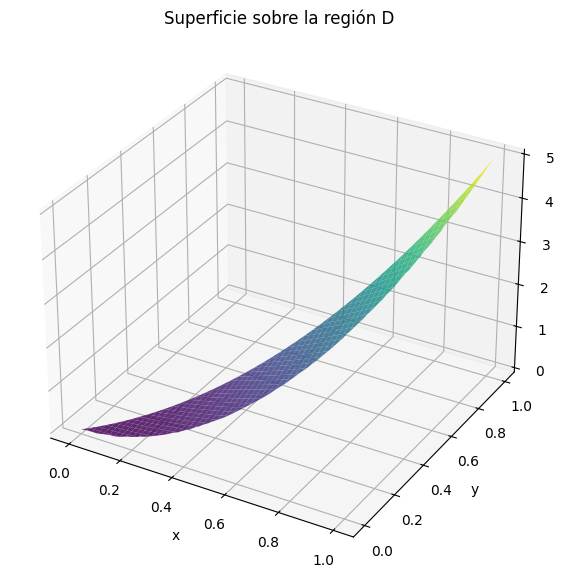

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Dominio
x = np.linspace(0, 1, 200)

y1 = x**2
y2 = x

# Malla
X, Y = np.meshgrid(
    np.linspace(0, 1, 200),
    np.linspace(0, 1, 200)
)

Z = X**2 + 3*X*Y + Y**2

# Máscara: región x^2 <= y <= x
mask = (Y >= X**2) & (Y <= X)

Z_masked = np.where(mask, Z, np.nan)

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    X,
    Y,
    Z_masked,
    cmap="viridis",
    alpha=0.85
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x,y)")

ax.set_title("Superficie sobre la región D")

plt.show()

La idea visual es:

$$
D
\longrightarrow
\text{superficie }z=f(x,y)
\longrightarrow
\text{volumen}
$$

# 5. Una aplicación muy importante: centro de masa

Para una lámina con densidad

$$
\rho(x,y),
$$

la masa es

$$
M=\iint_D \rho(x,y)\,dA.
$$

El centro de masa es

$$
\bar{x}
=
\frac{1}{M}
\iint_D x\rho(x,y)\,dA
$$

y

$$
\bar{y}
=
\frac{1}{M}
\iint_D y\rho(x,y)\,dA.
$$

Esto conecta directamente las integrales múltiples con:

* mecánica,
* robótica,
* simulación física,
* computer vision,
* geometría computacional.

# 6. Integrales triples

Ahora pasamos de una superficie a un volumen.

Tenemos

$$
f(x,y,z).
$$

Entonces

$$
\iiint_V f(x,y,z)\,dV.
$$

Si \(f=1\):

$$
\iiint_V1\,dV
=
\operatorname{Vol}(V).
$$

Si $f=\rho(x,y,z)$:

$$
\iiint_V\rho(x,y,z)\,dV
=
M.
$$

Es decir:

$$
\boxed{\text{integral triple de densidad = masa}}
$$

# 7. Ejemplo difícil de integral triple

Consideremos el tetraedro

$$
V=
\left\{
(x,y,z):
x\geq0,\,
y\geq0,\,
z\geq0,\,
x+y+z\leq1
\right\}.
$$

Queremos calcular

$$
I=
\iiint_V
x^2yz\,dV.
$$

Primero tenemos que entender el dominio.

De

$$
x+y+z\leq1
$$

obtenemos

$$
z\leq1-x-y.
$$

Entonces:

$$
0\leq x\leq1
$$

$$
0\leq y\leq1-x
$$

$$
0\leq z\leq1-x-y.
$$

Por tanto:

$$
I=
\int_0^1
\int_0^{1-x}
\int_0^{1-x-y}
x^2yz
\,dz\,dy\,dx.
$$

Este tipo de dominio aparece constantemente en problemas de:

* probabilidad,
* geometría,
* optimización,
* física matemática.

# 8. Visualizar el tetraedro con Python

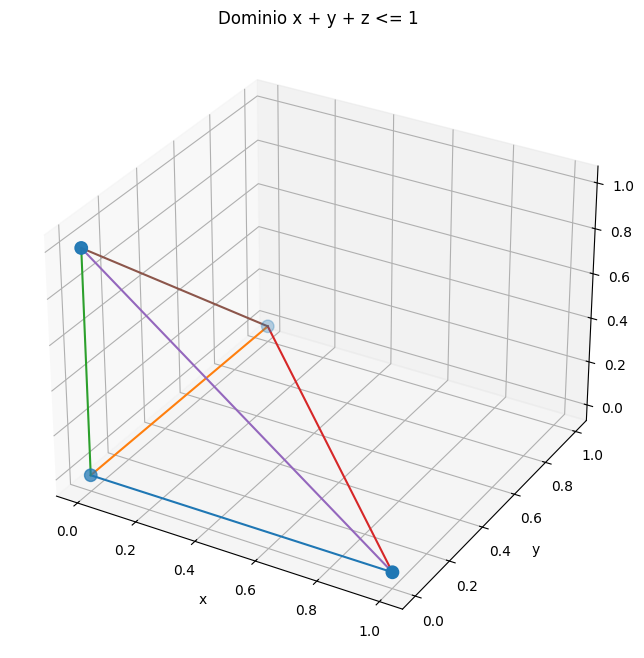

In [2]:
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")

# Puntos de los vértices
vertices = np.array([
    [0, 0, 0],
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
])

# Dibujar vértices
ax.scatter(
    vertices[:, 0],
    vertices[:, 1],
    vertices[:, 2],
    s=80
)

# Conectar aristas
edges = [
    (0, 1),
    (0, 2),
    (0, 3),
    (1, 2),
    (1, 3),
    (2, 3)
]

for i, j in edges:
    ax.plot(
        [vertices[i, 0], vertices[j, 0]],
        [vertices[i, 1], vertices[j, 1]],
        [vertices[i, 2], vertices[j, 2]]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Dominio x + y + z <= 1")

plt.show()

# 9. Cambio de variables

Esta es probablemente una de las partes **más importantes para SciML**.

Supongamos que tienes:

$$
\iint_D f(x,y)\,dx\,dy.
$$

Puedes introducir nuevas variables:

$$
x=x(u,v)
$$

$$
y=y(u,v).
$$

Entonces:

$$
\boxed{
dx\,dy
=
\left|
\frac{\partial(x,y)}
{\partial(u,v)}
\right|
du\,dv
}
$$

El término

$$
\left|
\frac{\partial(x,y)}
{\partial(u,v)}
\right|
$$

se llama **Jacobiano**.

# 10. ¿Por qué aparece el Jacobiano?

Esta es una idea fundamental.

Supongamos que tenemos un pequeño rectángulo:

$$
du\times dv.
$$

Cuando hacemos una transformación, ese pequeño rectángulo puede convertirse aproximadamente en un paralelogramo.

El área cambia.

El Jacobiano mide precisamente ese cambio local de área:

$$
dA
=
|J|\,du\,dv.
$$

Por eso:

$$
\boxed{
\text{Jacobiano}=
\text{factor local de cambio de área}
}
$$

Esto es extremadamente importante en aprendizaje automático porque las transformaciones de variables y los Jacobianos aparecen en:

* normalizing flows,
* cambio de distribución,
* inferencia bayesiana,
* transformaciones probabilísticas,
* simulaciones,
* optimización.

# 11. Ejemplo de cambio de variables

Consideremos

$$
I=
\iint_D
(x+y)e^{x+y}\,dA
$$

donde

$$
D:
0\leq x+y\leq2,
$$

$$
0\leq x-y\leq1.
$$

La región es incómoda en $(x,y)$.

Pero observamos que aparecen naturalmente:

$$
u=x+y
$$

$$
v=x-y.
$$

Entonces:

$$
x=\frac{u+v}{2}
$$

$$
y=\frac{u-v}{2}.
$$

El Jacobiano es

$$
J=
\begin{vmatrix}
\frac{\partial x}{\partial u}
&
\frac{\partial x}{\partial v}
\\
\frac{\partial y}{\partial u}
&
\frac{\partial y}{\partial v}
\end{vmatrix}.
$$

Es decir:

$$
J=
\begin{vmatrix}
\frac12 & \frac12\\
\frac12 &-\frac12
\end{vmatrix}.
$$

Por tanto:

$$
J=-\frac12.
$$

Así que:

$$
|J|=\frac12.
$$

La integral se convierte en:

$$
I=
\int_0^2
\int_0^1
u e^u
\frac12
\,dv\,du.
$$

¡Una región complicada se convirtió en un rectángulo!

Este es exactamente el tipo de transformación que debes aprender a reconocer.

# 12. Coordenadas polares

Las coordenadas cartesianas utilizan:

$$
(x,y).
$$

Las polares utilizan:

$$
(r,\theta).
$$

La transformación es:

$$
\boxed{x=r\cos\theta}
$$

$$
\boxed{y=r\sin\theta}
$$

y

$$
\boxed{dA=r\,dr\,d\theta}.
$$

Ese $(r)$ es el Jacobiano.

# 13. ¿Por qué $(dA=r\,dr\,d\theta)$?

Imagina un pequeño sector circular.

Su longitud aproximada es:

$$
r\,d\theta.
$$

Su grosor es:

$$
dr.
$$

Por tanto:

$$
dA
\approx
(r\,d\theta)(dr).
$$

Así:

$$
\boxed{dA=r\,dr\,d\theta}.
$$

# 14. Ejemplo difícil en polares

Calculemos:

$$
I=
\iint_D
e^{-(x^2+y^2)}
\,dA
$$

donde

$$
D:
1\leq x^2+y^2\leq4.
$$

La región es un anillo.

En cartesianas:

$$
1\leq x^2+y^2\leq4.
$$

Pero en polares:

$$
1\leq r^2\leq4
$$

por lo que

$$
1\leq r\leq2.
$$

Además:

$$
0\leq\theta\leq2\pi.
$$

Entonces:

$$
I=
\int_0^{2\pi}
\int_1^2
e^{-r^2}
r\,dr\,d\theta.
$$

La transformación convierte una geometría complicada en una extremadamente sencilla.

# 15. Python: visualizar un dominio polar

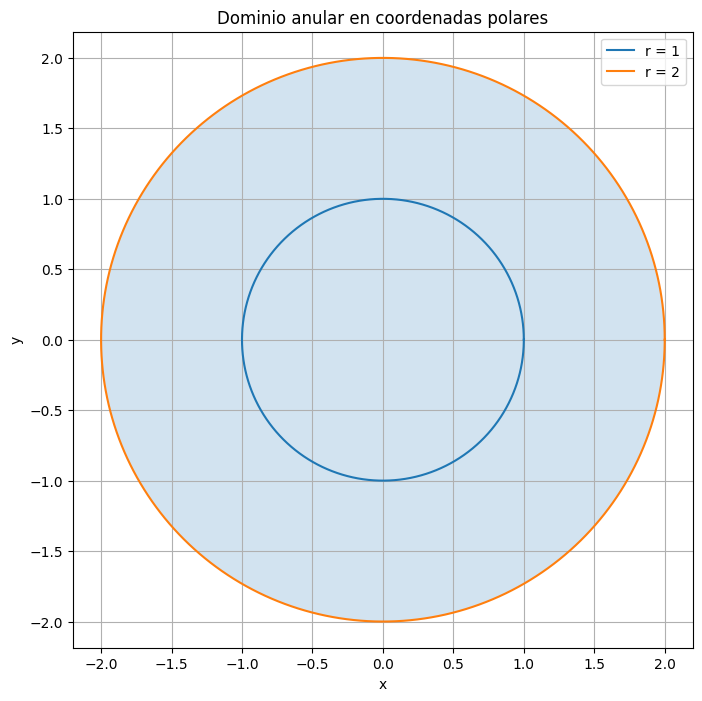

In [3]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, 2*np.pi, 500)

r_inner = 1
r_outer = 2

x_inner = r_inner * np.cos(theta)
y_inner = r_inner * np.sin(theta)

x_outer = r_outer * np.cos(theta)
y_outer = r_outer * np.sin(theta)

plt.figure(figsize=(8, 8))

plt.plot(x_inner, y_inner, label="r = 1")
plt.plot(x_outer, y_outer, label="r = 2")

plt.fill_between(
    x_outer,
    y_outer,
    alpha=0.2
)

plt.axis("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Dominio anular en coordenadas polares")
plt.legend()
plt.grid()

plt.show()

# 16. Un ejemplo mucho más interesante: Gaussiana 2D

Este aparece muchísimo en machine learning.

Consideremos:

$$
I=
\iint_{\mathbb R^2}
e^{-(x^2+y^2)}
\,dx\,dy.
$$

En cartesianas parece difícil.

Pero:

$$
x^2+y^2=r^2.
$$

Entonces:

$$
I=
\int_0^{2\pi}
\int_0^\infty
e^{-r^2}r\,dr\,d\theta.
$$

La integral radial:

$$
\int_0^\infty re^{-r^2}\,dr
$$

se resuelve usando

$$
u=r^2.
$$

Entonces:

$$
du=2r\,dr.
$$

Resultado:

$$
\int_0^\infty re^{-r^2}\,dr
=
\frac12.
$$

Por tanto:

$$
I
=
2\pi\frac12
=
\boxed{\pi}.
$$

Este resultado es importantísimo para entender distribuciones gaussianas.

# 17. Coordenadas cilíndricas

Ahora pasamos a 3D.

Las coordenadas cilíndricas son básicamente:

> coordenadas polares + altura.

Tenemos:

$$
\boxed{x=r\cos\theta}
$$

$$
\boxed{y=r\sin\theta}
$$

$$
\boxed{z=z}.
$$

Y:

$$
\boxed{dV=r\,dr\,d\theta\,dz}.
$$

# 18. ¿Cuándo usar cilíndricas?

Cuando el problema tiene simetría alrededor del eje $(z)$.

Por ejemplo:

$$
x^2+y^2\leq R^2.
$$

En cartesianas esto es un cilindro.

En cilíndricas:

$$
0\leq r\leq R.
$$

Muchísimo más sencillo.

# 19. Ejemplo difícil: masa de un cilindro con densidad variable

Consideremos:

$$
V:
x^2+y^2\leq4,
\qquad
0\leq z\leq3.
$$

Supongamos que la densidad es:

$$
\rho(x,y,z)
=
z(x^2+y^2).
$$

Queremos:

$$
M=
\iiint_V
z(x^2+y^2)\,dV.
$$

En cilíndricas:

$$
x^2+y^2=r^2.
$$

Por tanto:

$$
\rho=zr^2.
$$

Y:

$$
dV=r\,dr\,d\theta\,dz.
$$

Entonces:

$$
M=
\int_0^{2\pi}
\int_0^2
\int_0^3
zr^3
\,dz\,dr\,d\theta.
$$

Observa algo fundamental:

$$
\boxed{
r^2 \times r=r^3
}
$$

El segundo $(r)$ viene del Jacobiano.

# 20. Visualizar un cilindro con Python

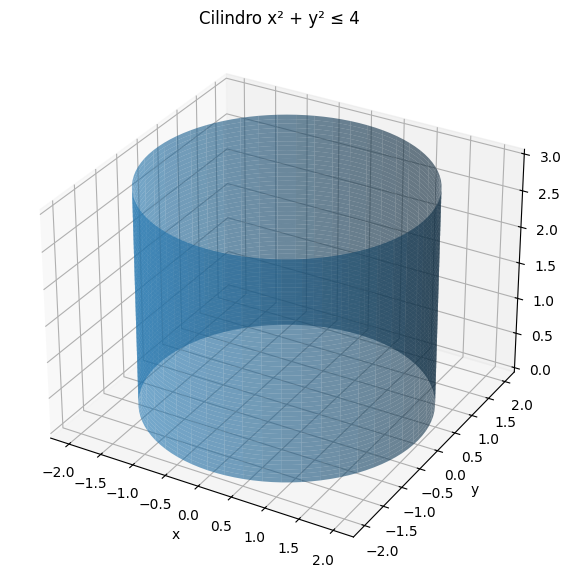

In [4]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, 2*np.pi, 100)
z = np.linspace(0, 3, 50)

Theta, Z = np.meshgrid(theta, z)

R = 2

X = R * np.cos(Theta)
Y = R * np.sin(Theta)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X,
    Y,
    Z,
    alpha=0.6
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Cilindro x² + y² ≤ 4")

plt.show()

# 21. Coordenadas esféricas

Ahora viene la transformación más importante para problemas con simetría radial.

Usamos:

$$
(\rho,\theta,\phi)
$$

donde típicamente:

* $(\rho)$: distancia al origen.
* $(\theta)$: ángulo azimutal.
* $(\phi)$: ángulo desde el eje $(z)$.

La transformación:

$$
\boxed{x=\rho\sin\phi\cos\theta}
$$

$$
\boxed{y=\rho\sin\phi\sin\theta}
$$

$$
\boxed{z=\rho\cos\phi}.
$$

Y el elemento de volumen:

$$
\boxed{
dV=
\rho^2\sin\phi
\,d\rho\,d\phi\,d\theta
}
$$

Este Jacobiano debes memorizarlo.

# 22. ¿Por qué aparece $(\rho^2\sin\phi)$?

El elemento de volumen puede imaginarse aproximadamente como:

$$
dV
\approx
d\rho
\cdot
(\rho\,d\phi)
\cdot
(\rho\sin\phi\,d\theta).
$$

Multiplicando:

$$
dV
=
\rho^2\sin\phi
\,d\rho\,d\phi\,d\theta.
$$

De nuevo:

$$
\boxed{\text{Jacobiano = cambio local de volumen}}
$$

# 23. Ejemplo difícil: integral sobre una esfera

Consideremos:

$$
I=
\iiint_V
(x^2+y^2+z^2)
e^{-(x^2+y^2+z^2)}
\,dV
$$

donde

$$
V:
x^2+y^2+z^2\leq R^2.
$$

En esféricas:

$$
x^2+y^2+z^2=\rho^2.
$$

Por tanto:

$$
I=
\iiint_V
\rho^2e^{-\rho^2}
\,dV.
$$

Usando el Jacobiano:

$$
I=
\int_0^{2\pi}
\int_0^\pi
\int_0^R
\rho^2e^{-\rho^2}
\rho^2\sin\phi
\,d\rho\,d\phi\,d\theta.
$$

Entonces:

$$
I=
\int_0^{2\pi}
\int_0^\pi
\int_0^R
\rho^4e^{-\rho^2}
\sin\phi
\,d\rho\,d\phi\,d\theta.
$$

Y lo mejor es que se separa:

$$
I=
\left(
\int_0^{2\pi}d\theta
\right)
\left(
\int_0^\pi\sin\phi\,d\phi
\right)
\left(
\int_0^R\rho^4e^{-\rho^2}d\rho
\right).
$$

Es decir:

$$
I=
(2\pi)(2)
\int_0^R\rho^4e^{-\rho^2}d\rho.
$$

Por tanto:

$$
\boxed{
I=4\pi
\int_0^R\rho^4e^{-\rho^2}d\rho
}
$$

La geometría prácticamente desapareció.

# 24. Python: esfera en coordenadas esféricas

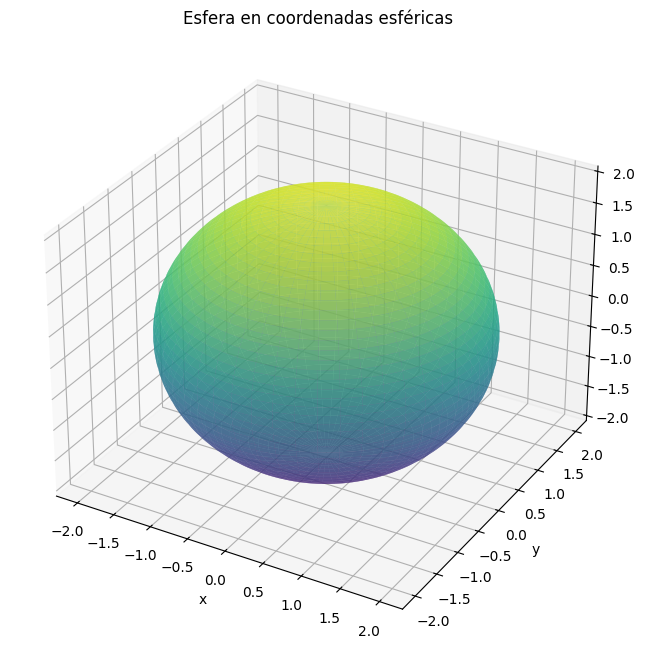

In [5]:
import numpy as np
import matplotlib.pyplot as plt

phi = np.linspace(0, np.pi, 100)
theta = np.linspace(0, 2*np.pi, 150)

Phi, Theta = np.meshgrid(phi, theta)

R = 2

X = R * np.sin(Phi) * np.cos(Theta)
Y = R * np.sin(Phi) * np.sin(Theta)
Z = R * np.cos(Phi)

fig = plt.figure(figsize=(9, 8))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X,
    Y,
    Z,
    alpha=0.65,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Esfera en coordenadas esféricas")

plt.show()

# 25. ¿Cuándo utilizar cada sistema?

Esta tabla es fundamental:

| Problema                    | Sistema recomendado   |
| --------------------------- | --------------------- |
| Rectángulos                 | Cartesianas           |
| Cuadrados                   | Cartesianas           |
| Regiones $(x+y\leq c)$      | Cartesianas           |
| Círculos                    | Polares               |
| Anillos                     | Polares               |
| Simetría alrededor de $(z)$ | Cilíndricas           |
| Cilindros                   | Cilíndricas           |
| Conos                       | Cilíndricas/esféricas |
| Esferas                     | Esféricas             |
| Distribuciones radiales     | Esféricas             |
| $(x^2+y^2)$                 | Polares/cilíndricas   |
| $(x^2+y^2+z^2)$             | Esféricas             |

Una regla muy útil:

$$
\boxed{
x^2+y^2
\rightarrow r^2
}
$$

y

$$
\boxed{
x^2+y^2+z^2
\rightarrow \rho^2
}
$$

# 26. Aplicación directa a Scientific Machine Learning

Aquí empieza la parte realmente interesante.

En SciML, una función puede representar un campo:

$$
u(x,y,z).
$$

Por ejemplo, temperatura:

$$
T(x,y,z).
$$

La temperatura promedio de un volumen es:

$$
\bar T
=
\frac{1}{V}
\iiint_V T(x,y,z)\,dV.
$$

Esto aparece en simulación de:

* transferencia de calor,
* fluidos,
* materiales,
* electromagnetismo.

# 27. Ejemplo de vida real: temperatura de una habitación

Imagina una habitación:

$$
0\leq x\leq10
$$

$$
0\leq y\leq8
$$

$$
0\leq z\leq3.
$$

Supongamos que la temperatura es:

$$
T(x,y,z)
=
20
+
0.5x
-
0.2y
+
2z
+
\sin\left(\frac{\pi x}{10}\right).
$$

La temperatura promedio es:

$$
\bar T
=
\frac{1}{240}
\int_0^{10}
\int_0^8
\int_0^3
T(x,y,z)
\,dz\,dy\,dx.
$$

Esto es literalmente un problema de **integral triple aplicada a un campo físico**.

En SciML podrías después aprender una red neuronal que aproxime:

$$
T_\theta(x,y,z).
$$

Y entonces podrías calcular:

$$
\bar T
\approx
\frac1V
\iiint_V
T_\theta(x,y,z)\,dV.
$$

Ahí las integrales múltiples pasan directamente al mundo de ML.

# 28. Aplicación todavía más importante: probabilidad

Supongamos dos variables aleatorias:

$$
X,Y.
$$

Su densidad conjunta es:

$$
p(x,y).
$$

Debe cumplirse:

$$
\iint_{\mathbb R^2}
p(x,y)\,dx\,dy=1.
$$

Y una esperanza:

$$
E[g(X,Y)]
=
\iint
g(x,y)p(x,y)\,dx\,dy.
$$

Por ejemplo:

$$
E[X^2+Y^2]
=
\iint
(x^2+y^2)p(x,y)
\,dx\,dy.
$$

Esto conecta las integrales múltiples directamente con:

* Machine Learning,
* Bayesian ML,
* Gaussian Processes,
* variational inference,
* normalizing flows,
* modelos probabilísticos.

# 29. Conexión con normalizing flows

Esta conexión te va a resultar especialmente importante más adelante.

Supongamos que transformamos:

$$
z=T(x).
$$

Una densidad cambia según:

$$
p_X(x)
=
p_Z(T(x))
\left|
\det J_T(x)
\right|.
$$

Dependiendo de la dirección de la transformación, también puedes encontrar:

$$
p_X(x)
=
p_Z(z)
\left|
\det\frac{\partial z}{\partial x}
\right|.
$$

¿Reconoces el término?

Es el mismo concepto que apareció en:

$$
dx\,dy
=
|J|\,du\,dv.
$$

Por eso aprender bien **cambio de variables + Jacobianos** te prepara para una parte importante de ML moderno.

# 30. Una forma de pensar todo el tema

Te recomiendo construir este mapa mental:

```text
                 INTEGRALES MÚLTIPLES
                         │
          ┌──────────────┼──────────────┐
          │              │              │
       Dobles         Triples        Probabilidad
          │              │              │
         dA             dV            densidades
          │              │              │
          └──────────────┼──────────────┘
                         │
                 CAMBIO DE VARIABLES
                         │
                    JACOBIANO
                         │
       ┌─────────────────┼─────────────────┐
       │                 │                 │
    Polares          Cilíndricas       Esféricas
       │                 │                 │
      r                 r,z              ρ,θ,φ
       │                 │                 │
     círculos         cilindros          esferas
```

# 31. Fórmulas que debes dominar

## Cartesianas 2D

$$
\boxed{dA=dx\,dy}
$$

## Cartesianas 3D

$$
\boxed{dV=dx\,dy\,dz}
$$

## Polares

$$
\boxed{x=r\cos\theta}
$$

$$
\boxed{y=r\sin\theta}
$$

$$
\boxed{dA=r\,dr\,d\theta}
$$

## Cilíndricas

$$
\boxed{x=r\cos\theta}
$$

$$
\boxed{y=r\sin\theta}
$$

$$
\boxed{z=z}
$$

$$
\boxed{dV=r\,dr\,d\theta\,dz}
$$

## Esféricas

$$
\boxed{x=\rho\sin\phi\cos\theta}
$$

$$
\boxed{y=\rho\sin\phi\sin\theta}
$$

$$
\boxed{z=\rho\cos\phi}
$$

$$
\boxed{
dV=\rho^2\sin\phi\,d\rho\,d\phi\,d\theta
}
$$

# 32. Python para comprobar integrales simbólicamente

Puedes utilizar `SymPy`.

Por ejemplo:

In [6]:
import sympy as sp

x, y = sp.symbols("x y")

f = x**2 + 3*x*y + y**2

integral = sp.integrate(
    sp.integrate(
        f,
        (y, x**2, x)
    ),
    (x, 0, 1)
)

print(integral)
print(sp.N(integral))

59/280
0.210714285714286


Esto te permite hacer:

$$
\text{cálculo analítico}
\leftrightarrow
\text{verificación computacional}.
$$

# 33. Y para SciML: integración numérica

Más adelante no siempre tendrás una función integrable analíticamente.

Podrías tener:

$$
u_\theta(x,y,z)
$$

producida por una red neuronal.

Entonces necesitas aproximar:

$$
\iiint_Vu_\theta(x,y,z)dV.
$$

Una técnica básica es Monte Carlo.

Generamos puntos:

$$
x_1,\ldots,x_N.
$$

Entonces:

$$
\int_D f(x)dV
\approx
\operatorname{Vol}(D)
\frac1N
\sum_{i=1}^N f(x_i).
$$

Esto es **muy importante para SciML**, porque conecta:

$$
\boxed{
\text{integrales}
\rightarrow
\text{muestreo}
\rightarrow
\text{Monte Carlo}
\rightarrow
\text{ML}
}
$$

# 34. Ejemplo Monte Carlo

Supongamos una esfera:

$$
x^2+y^2+z^2\leq1.
$$

Queremos estimar su volumen.

Sabemos analíticamente:

$$
V=\frac43\pi.
$$

Pero podemos aproximarlo computacionalmente.

In [7]:
import numpy as np

N = 2_000_000

points = np.random.uniform(-1, 1, size=(N, 3))

inside = np.sum(points**2, axis=1) <= 1

fraction = np.mean(inside)

cube_volume = 8

volume_estimated = cube_volume * fraction

volume_exact = 4*np.pi/3

print("Monte Carlo:", volume_estimated)
print("Exacto:", volume_exact)
print("Error:", abs(volume_estimated - volume_exact))

Monte Carlo: 4.189604
Exacto: 4.1887902047863905
Error: 0.0008137952136095805


Aquí acabas de usar:

$$
\boxed{
\text{integración multidimensional}
+
\text{probabilidad}
+
\text{computación}
}
$$

que es una combinación muy relevante en Scientific Machine Learning.

| **Inicio**         | **atrás 4**                          | **Siguiente 6**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./4_4_Hessiano.ipynb) | [⏩](./4_6_Calculo_vectorial.ipynb) |